# Ejercicio 2 — Predicción de niveles de glucosa en sangre

**Laboratorio de Minería de Datos — metodología CRISP-DM**

Fases: 1) comprensión del negocio · 2) comprensión de los datos · 3) preparación · 4) modelado · 5) evaluación · 6) despliegue (exportación del modelo e interfaz web).

## 1. Comprensión del negocio

Se quiere estimar el **nivel de glucosa en sangre** (`Nivel_Glucosa`, en mg/dL) de un paciente a partir de:

| Variable | Significado |
|---|---|
| `Edad` | Edad del paciente, en años |
| `IMC` | Índice de masa corporal |
| `Actividad_Fisica` | Horas semanales de ejercicio |

**Preguntas a responder:** ¿qué tan bien predice el modelo la glucosa?, ¿cuál es la importancia de cada variable?, ¿cuál tiene **mayor impacto**?, y ¿cuál es su MSE y su R²?

In [1]:
# Configuración del ejercicio
ARCHIVO = "glucosa_data.csv"
PREFIJO = "glucosa"
OBJETIVO = "Nivel_Glucosa"
VARIABLES = ["Edad", "IMC", "Actividad_Fisica"]
UNIDAD = "mg/dL"
# Cambio realista de cada variable para leer su coeficiente
PASOS = {
    "Edad": (1, "1 año más de edad"),
    "IMC": (1, "1 punto más de IMC"),
    "Actividad_Fisica": (1, "1 hora más de ejercicio a la semana"),
}

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data"
MODELOS = RAIZ / "modelos"
FIGURAS = RAIZ / "figuras"
MODELOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)

SEMILLA = 42  # misma partición de datos cada vez que se ejecuta
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.4f}".format)

## 2. Comprensión de los datos

In [3]:
df = pd.read_csv(DATOS / ARCHIVO)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 2,000 | Columnas: 4


,Edad,IMC,Actividad_Fisica,Nivel_Glucosa
0,42,13.4664,1,141.8403
1,67,23.4556,1,171.9374
2,71,25.7652,8,155.5042
3,48,24.0795,2,115.8652
4,35,24.4266,7,115.6987


In [4]:
print("Tipos de dato:")
print(df.dtypes.to_string())
print("\nValores nulos por columna:")
print(df.isna().sum().to_string())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

Tipos de dato:
Edad                  int64
IMC                 float64
Actividad_Fisica      int64
Nivel_Glucosa       float64

Valores nulos por columna:
Edad                0
IMC                 0
Actividad_Fisica    0
Nivel_Glucosa       0

Filas duplicadas: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Edad,"2,000.0000",49.1570,17.5445,20.0000,34.0000,50.0000,64.0000,79.0000
IMC,"2,000.0000",24.9633,3.9836,10.5867,22.3445,25.0287,27.7511,39.4302
Actividad_Fisica,"2,000.0000",4.6645,2.9122,0.0000,2.0000,5.0000,7.0000,9.0000
Nivel_Glucosa,"2,000.0000",139.6301,27.3429,43.4159,119.0676,139.9673,159.2085,227.5607


### Correlación entre variables

El coeficiente de correlación de Pearson (r) va de −1 a 1 y mide qué tan lineal es la relación entre dos variables.

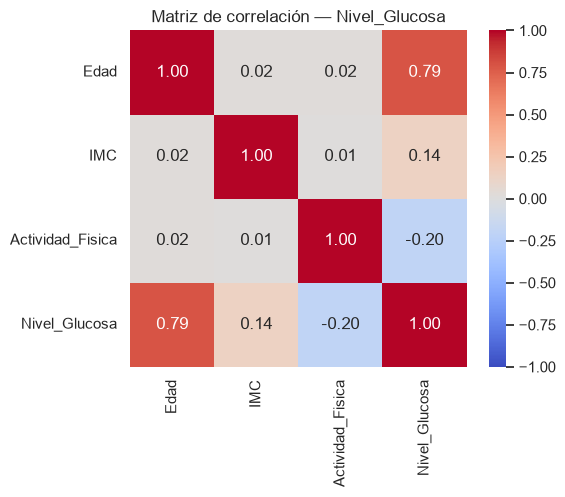

,r con Nivel_Glucosa
Edad,0.7898
Actividad_Fisica,-0.1984
IMC,0.1383


In [6]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title(f"Matriz de correlación — {OBJETIVO}")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_correlacion.png", dpi=150); plt.show()

corr[OBJETIVO].drop(OBJETIVO).sort_values(key=abs, ascending=False).rename(f"r con {OBJETIVO}").to_frame()

## 3. Preparación de los datos

Se revisan valores atípicos con la regla del rango intercuartílico (IQR): un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

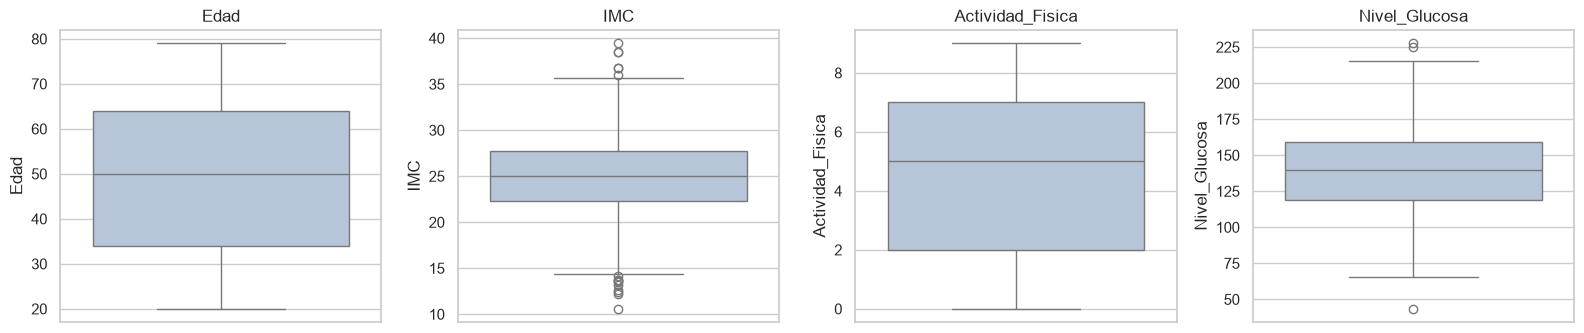

,atípicos (IQR),mínimo,máximo
Edad,0,20.0000,79.0000
IMC,16,10.5867,39.4302
Actividad_Fisica,0,0.0000,9.0000
Nivel_Glucosa,3,43.4159,227.5607


In [7]:
def contar_atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())


atipicos = pd.DataFrame({
    "atípicos (IQR)": {c: contar_atipicos_iqr(df[c]) for c in df.columns},
    "mínimo": df.min(),
    "máximo": df.max(),
})

fig, ejes = plt.subplots(1, len(df.columns), figsize=(4 * len(df.columns), 3.5))
for ax, columna in zip(ejes, df.columns):
    sns.boxplot(y=df[columna], ax=ax, color="lightsteelblue")
    ax.set_title(columna)
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_cajas.png", dpi=150); plt.show()
atipicos

**Decisión de limpieza:** no hay nulos ni duplicados. La regla IQR marca 16 valores de `IMC` (por fuera de 14,2–35,9) y 3 de `Nivel_Glucosa` (por fuera de 58,9–219,4 mg/dL). Son valores extremos pero clínicamente posibles: delgadez severa u obesidad, hipoglucemia o hiperglucemia. Eliminarlos haría que el modelo ignorara justo a los pacientes de riesgo, así que **se conservan las 2.000 filas**.

### Partición entrenamiento / prueba

El 80 % de las filas se usa para entrenar y el 20 % se guarda para evaluar con datos que el modelo no ha visto.

In [8]:
X = df[VARIABLES]
y = df[OBJETIVO]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train):,} filas | Prueba: {len(X_test):,} filas")

Entrenamiento: 1,600 filas | Prueba: 400 filas


## 4. Modelado — regresión lineal múltiple

El modelo tiene la forma  ŷ = β₀ + β₁·x₁ + β₂·x₂ + β₃·x₃  y se ajusta por mínimos cuadrados ordinarios con `scikit-learn`.

In [9]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

terminos = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):,.4f}·{v}" for v, c in zip(VARIABLES, modelo.coef_))
print("Ecuación del modelo:")
print(f"{OBJETIVO} = {modelo.intercept_:,.4f} {terminos}")

Ecuación del modelo:
Nivel_Glucosa = 65.8609 + 1.2266·Edad + 0.9334·IMC - 2.0853·Actividad_Fisica


Se ajusta el mismo modelo con `statsmodels` para obtener los **p-valores** (si un coeficiente es estadísticamente distinto de cero) y el **VIF** (multicolinealidad: un VIF mayor que 5 indica que las variables se solapan entre sí).

In [10]:
X_train_const = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_const).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:          Nivel_Glucosa   R-squared:                       0.686
Model:                            OLS   Adj. R-squared:                  0.686
Method:                 Least Squares   F-statistic:                     1163.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:29:25   Log-Likelihood:                -6639.7
No. Observations:                1600   AIC:                         1.329e+04
Df Residuals:                    1596   BIC:                         1.331e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               65.8609      2.701  

In [11]:
vif = pd.Series(
    [variance_inflation_factor(X_train_const.values, i) for i in range(1, X_train_const.shape[1])],
    index=VARIABLES,
    name="VIF",
)
vif.to_frame()

,VIF
Edad,1.0005
IMC,1.0004
Actividad_Fisica,1.0003


## 5. Evaluación del modelo

In [12]:
def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_real, y_pred), "R2": r2_score(y_real, y_pred)}


pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
m_train = metricas(y_train, pred_train)
m_test = metricas(y_test, pred_test)

kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
r2_cv = cross_val_score(LinearRegression(), X, y, cv=kfold, scoring="r2")

pd.DataFrame({"Entrenamiento": m_train, "Prueba": m_test}).rename(index={"R2": "R²"})

,Entrenamiento,Prueba
MSE,235.5137,233.6930
RMSE,15.3465,15.2870
MAE,12.1093,12.2198
R²,0.6862,0.6814


In [13]:
print(f"R² con validación cruzada (5 pliegues): {r2_cv.mean():.4f} ± {r2_cv.std():.4f}\n")
print(f"• El modelo explica el {m_test['R2']:.1%} de la variación de {OBJETIVO} en datos que no vio al entrenar.")
print(f"• MSE = {m_test['MSE']:,.2f} ({UNIDAD})²: promedio de los errores al cuadrado.")
print(f"• RMSE = {m_test['RMSE']:,.2f} {UNIDAD}: error típico en las unidades originales "
      f"({m_test['RMSE'] / y.mean():.1%} del promedio de {OBJETIVO}, que es {y.mean():,.2f} {UNIDAD}).")
print(f"• MAE = {m_test['MAE']:,.2f} {UNIDAD}: en promedio la predicción se aleja eso del valor real.")
diferencia = m_train["R2"] - m_test["R2"]
print(f"• R² entrenamiento − R² prueba = {diferencia:+.4f} → "
      + ("no hay señales de sobreajuste." if abs(diferencia) < 0.05 else "revisar posible sobreajuste."))

R² con validación cruzada (5 pliegues): 0.6833 ± 0.0070

• El modelo explica el 68.1% de la variación de Nivel_Glucosa en datos que no vio al entrenar.
• MSE = 233.69 (mg/dL)²: promedio de los errores al cuadrado.
• RMSE = 15.29 mg/dL: error típico en las unidades originales (10.9% del promedio de Nivel_Glucosa, que es 139.63 mg/dL).
• MAE = 12.22 mg/dL: en promedio la predicción se aleja eso del valor real.
• R² entrenamiento − R² prueba = +0.0048 → no hay señales de sobreajuste.


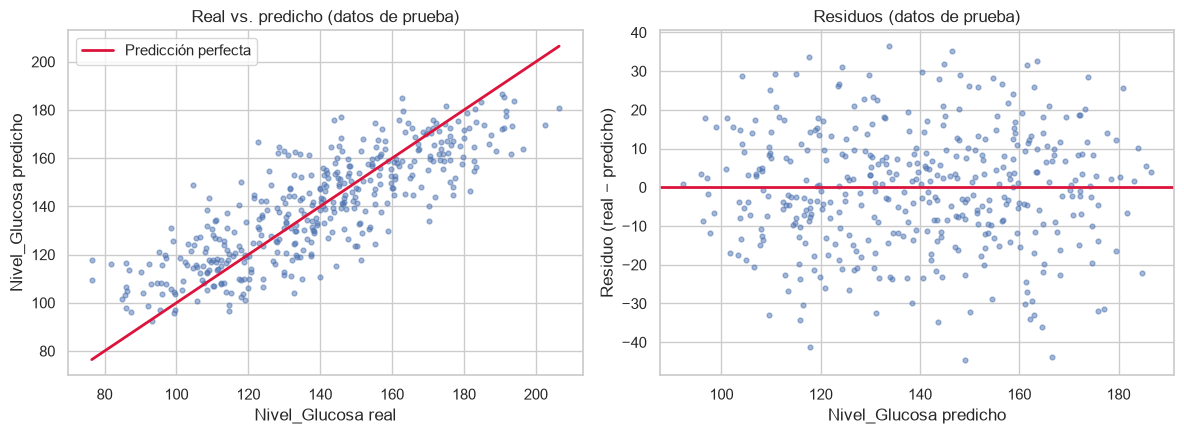

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].scatter(y_test, pred_test, alpha=0.5, s=12)
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ejes[0].plot(limites, limites, color="crimson", lw=2, label="Predicción perfecta")
ejes[0].set(xlabel=f"{OBJETIVO} real", ylabel=f"{OBJETIVO} predicho", title="Real vs. predicho (datos de prueba)")
ejes[0].legend()

residuos = y_test - pred_test
ejes[1].scatter(pred_test, residuos, alpha=0.5, s=12)
ejes[1].axhline(0, color="crimson", lw=2)
ejes[1].set(xlabel=f"{OBJETIVO} predicho", ylabel="Residuo (real − predicho)", title="Residuos (datos de prueba)")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_evaluacion.png", dpi=150); plt.show()

### Interpretación de los coeficientes e importancia de cada variable

- **Coeficiente:** cuánto cambia la predicción cuando la variable sube una unidad y las demás se mantienen fijas.
- **Coeficiente estandarizado (β):** el mismo efecto medido en desviaciones estándar; como no depende de las unidades, permite **comparar qué variable pesa más**.
- **Efecto en el rango típico:** cuánto cambia la predicción al pasar la variable de su percentil 25 a su percentil 75 (el 50 % central de los datos).

In [15]:
desv_y = y_train.std()
coeficientes = pd.DataFrame({
    "coeficiente": modelo.coef_,
    "coef_estandarizado": [c * X_train[v].std() / desv_y for v, c in zip(VARIABLES, modelo.coef_)],
    "efecto_rango_típico": [c * (X[v].quantile(0.75) - X[v].quantile(0.25)) for v, c in zip(VARIABLES, modelo.coef_)],
    "p_valor": ols.pvalues[VARIABLES].values,
}, index=VARIABLES)
coeficientes["importancia_%"] = 100 * coeficientes["coef_estandarizado"].abs() / coeficientes["coef_estandarizado"].abs().sum()
coeficientes = coeficientes.sort_values("importancia_%", ascending=False)
coeficientes

,coeficiente,coef_estandarizado,efecto_rango_típico,p_valor,importancia_%
Edad,1.2266,0.7874,36.7977,0.0000,68.6980
Actividad_Fisica,-2.0853,-0.2229,-10.4264,0.0000,19.4466
IMC,0.9334,0.1359,5.0463,0.0000,11.8554


In [16]:
print(f"Intercepto (β₀) = {modelo.intercept_:,.4f} {UNIDAD}: valor teórico de {OBJETIVO} si todas las variables valieran 0.\n")
for variable, fila in coeficientes.iterrows():
    paso, texto = PASOS[variable]
    efecto = fila["coeficiente"] * paso
    direccion = "sube" if efecto >= 0 else "baja"
    significancia = "significativo" if fila["p_valor"] < 0.05 else "NO significativo"
    print(f"• {variable}: con {texto}, {OBJETIVO} {direccion} {abs(efecto):,.4f} {UNIDAD}, "
          f"manteniendo fijas las demás variables.")
    print(f"  p-valor = {fila['p_valor']:.3g} ({significancia} al 5 %) | importancia relativa = {fila['importancia_%']:.1f} %\n")
print(f"Variable con MAYOR impacto: {coeficientes.index[0]} "
      f"(β estandarizado = {coeficientes['coef_estandarizado'].iloc[0]:+.3f}).")

Intercepto (β₀) = 65.8609 mg/dL: valor teórico de Nivel_Glucosa si todas las variables valieran 0.

• Edad: con 1 año más de edad, Nivel_Glucosa sube 1.2266 mg/dL, manteniendo fijas las demás variables.
  p-valor = 0 (significativo al 5 %) | importancia relativa = 68.7 %

• Actividad_Fisica: con 1 hora más de ejercicio a la semana, Nivel_Glucosa baja 2.0853 mg/dL, manteniendo fijas las demás variables.
  p-valor = 6.52e-53 (significativo al 5 %) | importancia relativa = 19.4 %

• IMC: con 1 punto más de IMC, Nivel_Glucosa sube 0.9334 mg/dL, manteniendo fijas las demás variables.
  p-valor = 1.31e-21 (significativo al 5 %) | importancia relativa = 11.9 %

Variable con MAYOR impacto: Edad (β estandarizado = +0.787).


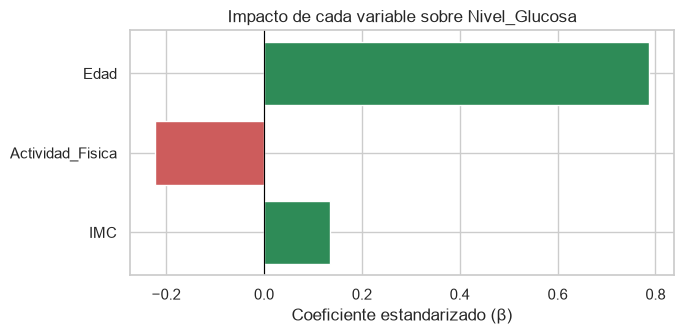

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.5))
orden = coeficientes.iloc[::-1]
colores = ["seagreen" if c >= 0 else "indianred" for c in orden["coef_estandarizado"]]
ax.barh(orden.index, orden["coef_estandarizado"], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Coeficiente estandarizado (β)", title=f"Impacto de cada variable sobre {OBJETIVO}")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_importancia.png", dpi=150); plt.show()

## 6. Relación de cada variable independiente con la variable dependiente

Cada punto es una observación. La línea roja es la recta de regresión simple de esa variable sola contra la variable dependiente.

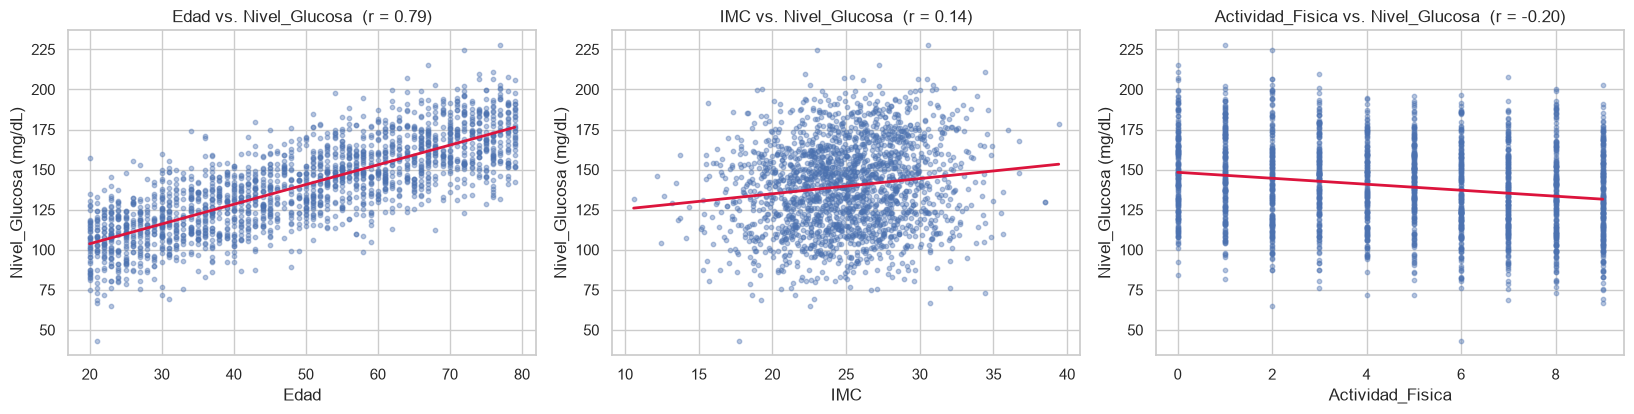

In [18]:
fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(5.5 * len(VARIABLES), 4.3))
transparencia = 0.15 if len(df) > 5000 else 0.4
for ax, variable in zip(ejes, VARIABLES):
    ax.scatter(df[variable], df[OBJETIVO], alpha=transparencia, s=10)
    pendiente, corte = np.polyfit(df[variable], df[OBJETIVO], 1)
    xs = np.linspace(df[variable].min(), df[variable].max(), 100)
    ax.plot(xs, corte + pendiente * xs, color="crimson", lw=2)
    r = df[variable].corr(df[OBJETIVO])
    ax.set(xlabel=variable, ylabel=f"{OBJETIVO} ({UNIDAD})", title=f"{variable} vs. {OBJETIVO}  (r = {r:.2f})")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_dispersion.png", dpi=150); plt.show()

## 7. Exportación del modelo

En Python hay dos formas habituales de guardar un modelo entrenado:

| | `pickle` | `joblib` |
|---|---|---|
| Qué es | Módulo estándar de Python | Librería que usa scikit-learn |
| Guardar | `pickle.dump(obj, open("m.pkl", "wb"))` | `joblib.dump(obj, "m.joblib")` |
| Cargar | `pickle.load(open("m.pkl", "rb"))` | `joblib.load("m.joblib")` |
| Ventaja | No requiere instalar nada | Más eficiente con arreglos grandes de NumPy |

Se usa **joblib**, que es lo que recomienda la documentación de scikit-learn. Junto al modelo se guardan las variables, las métricas, los coeficientes y los rangos de los datos, para que la interfaz web pueda mostrarlos. Solo se guardan objetos de scikit-learn y tipos básicos de Python, así que la app no necesita el código de este notebook para cargarlo. Al cargarlo se debe usar la **misma versión de scikit-learn** (queda registrada en el archivo).

In [19]:
artefacto = {
    "modelo": modelo,
    "variables": VARIABLES,
    "objetivo": OBJETIVO,
    "unidad": UNIDAD,
    "intercepto": float(modelo.intercept_),
    "coeficientes": {v: float(c) for v, c in zip(VARIABLES, modelo.coef_)},
    "coef_estandarizados": coeficientes["coef_estandarizado"].astype(float).to_dict(),
    "p_valores": coeficientes["p_valor"].astype(float).to_dict(),
    "metricas_prueba": {k: float(v) for k, v in m_test.items()},
    "metricas_entrenamiento": {k: float(v) for k, v in m_train.items()},
    "r2_validacion_cruzada": {"media": float(r2_cv.mean()), "desviacion": float(r2_cv.std())},
    "rangos": {
        v: {"min": float(df[v].min()), "max": float(df[v].max()), "mediana": float(df[v].median())}
        for v in VARIABLES
    },
    "filas": {"entrenamiento": len(X_train), "prueba": len(X_test)},
    "version_sklearn": sklearn.__version__,
}

ruta_modelo = MODELOS / f"modelo_{PREFIJO}.joblib"
joblib.dump(artefacto, ruta_modelo)
print(f"Modelo guardado en {ruta_modelo.relative_to(RAIZ)} ({ruta_modelo.stat().st_size / 1024:.1f} KB)")

Modelo guardado en modelos\modelo_glucosa.joblib (1.6 KB)


Se carga el archivo de nuevo y se comprueba que predice exactamente lo mismo que el modelo original:

In [20]:
cargado = joblib.load(ruta_modelo)
ejemplo = X_test.head(5)
comparacion = ejemplo.copy()
comparacion[f"{OBJETIVO} real"] = y_test.head(5).values
comparacion["predicción (modelo original)"] = modelo.predict(ejemplo)
comparacion["predicción (modelo cargado)"] = cargado["modelo"].predict(ejemplo)
assert np.allclose(comparacion["predicción (modelo original)"], comparacion["predicción (modelo cargado)"])
comparacion

,Edad,IMC,Actividad_Fisica,Nivel_Glucosa real,predicción (modelo original),predicción (modelo cargado)
1860,21,21.3538,5,119.0386,101.1240,101.1240
353,27,23.2263,7,119.9908,106.0607,106.0607
1333,56,34.8500,4,158.9492,158.7369,158.7369
905,43,30.5844,6,122.8663,134.6392,134.6392
1289,67,23.9879,7,140.7524,155.8351,155.8351


## 8. Conclusiones

1. **Desempeño:** el modelo explica el **68,1 %** de la variación de la glucosa en los datos de prueba (R² = 0,6814), con un **MSE de 233,69** y un RMSE de 15,29 mg/dL (10,9 % del promedio, 139,63 mg/dL). El R² de entrenamiento (0,6862) y el de validación cruzada (0,6833 ± 0,0070) son parecidos: no hay sobreajuste. El 32 % restante depende de factores que no están en los datos (dieta, genética, medicación, etc.).
2. **Interpretación de los coeficientes** (las tres variables son significativas, p < 0,05):
   - `Edad`: cada año adicional **sube** la glucosa 1,23 mg/dL.
   - `IMC`: cada punto adicional **sube** la glucosa 0,93 mg/dL.
   - `Actividad_Fisica`: cada hora semanal de ejercicio **baja** la glucosa 2,09 mg/dL.
3. **Importancia de cada variable:** Edad 68,7 %, Actividad física 19,4 % e IMC 11,9 %, según el coeficiente estandarizado.
4. **Variable de mayor impacto: la Edad** (β = 0,787, r = 0,79). Pasar del percentil 25 al 75 de edad sube la glucosa unos 36,8 mg/dL, frente a −10,4 mg/dL de la actividad física y +5,0 mg/dL del IMC.
5. **Lectura práctica:** la edad no se puede cambiar, pero la actividad física sí, y es la segunda variable más importante. Tres horas más de ejercicio a la semana se asocian con unos 6,3 mg/dL menos de glucosa. Es una asociación en los datos, no una prueba de causa y efecto.